# Task 2.2: Hyperparameter Tuning for Rainfall Prediction
## Singapore Rainfall, 2017–2024

This notebook compares Gradient-Boosted Tree (GBT) configurations using Spark MLlib to select a model for predicting whether rainfall will exceed a specified threshold over the next 30 minutes. It uses the features and sampled datasets prepared in Task 2.1, with **2017–2022 for training** and **2023 for validation**.

The tuning process covers:

- **Model pipeline:** Combine the 12 features using `VectorAssembler` and train a `GBTClassifier`.
- **Hyperparameter search:** Test 27 combinations of maximum tree depth, learning rate, and boosting iterations.
- **Validation performance:** Calculate PR-AUC and ROC-AUC separately for rainfall thresholds of **0, 1, 2.5, 5, and 10 mm**.
- **Configuration selection:** Select the configuration with the highest mean validation PR-AUC, giving equal weight to each threshold.
- **Training time and interpretation:** Record model training time and examine the selected model’s feature importance.

The experiment results, selected model, and feature-importance scores are saved to Google Cloud Storage. The selected configuration is then used for final retraining and evaluation in Task 2.3. The **2024 test sample is not used to choose the configuration**.

## 2.2.1 Spark Session

In [ ]:
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from itertools import product

import matplotlib.pyplot as plt

import time
import uuid

In [2]:
# Use the existing Dataproc cluster.
spark = (
    SparkSession.builder
    .appName("Rainfall_GBT_Experiments")
    .getOrCreate()
)
 
spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")
spark.conf.set("spark.sql.shuffle.partitions", "128")
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true")

ML_PARTITIONS = 32
 
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("Training partitions:", ML_PARTITIONS)
 

Spark version: 3.5.3
Spark master: yarn
Shuffle partitions: 128
Training partitions: 32


26/10/15 14:32:15 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


## 2.2.2 Reading the Train, Validation and Test Datasets

In [3]:
train_final = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/train_parquet/")
val_final = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/val_parquet/")
test_final = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/test_parquet/")

## 2.2.3 Grid Search to Find the Best Hyperparameters

This section compares GBT configurations to identify the settings that achieve the highest mean validation PR-AUC. Models are trained on the prepared 2017–2022 sample and evaluated on the 2023 validation sample.

The grid search tests **27 combinations** of:

- **Maximum tree depth:** 3, 5, and 7.
- **Learning rate:** 0.01, 0.05, and 0.1.
- **Boosting iterations:** 50, 100, and 150.

For each configuration, PR-AUC and ROC-AUC are calculated separately for the rainfall thresholds of **0, 1, 2.5, 5, and 10 mm**. The 5 PR-AUC scores are then averaged, giving each threshold equal weight. The configuration with the highest average is selected.

Training time is recorded for each configuration. Results and the best-performing model are saved to Google Cloud Storage for subsequent analysis and final retraining. The 2024 test sample is not used to select the configuration.

In [ ]:
feature_cols = [
    "location_latitude",
    "location_longitude",
    "hour",
    "month",
    "reading_value",
    "lag_5m",
    "lag_30m",
    "lag_1h",
    "rain_cumsum_30m",
    "rain_cumsum_1h",
    "wet_count_30m",
    "thr"
]

THRESHOLDS = [0.0, 1.0, 2.5, 5.0, 10.0]

### Defining the Training and Evaluation Function

The `train_gbt(depth, learning_rate, iterations)` function trains and evaluates 1 GBT configuration. It combines the 12 features into a vector, fits the model on the training sample, and records the training time.

The model is then evaluated on the validation sample using PR-AUC and ROC-AUC, calculated separately for each rainfall threshold. The parameters, scores, and training time are saved to Google Cloud Storage.

The function returns the trained model and the mean PR-AUC across the 5 thresholds. This average is used to compare configurations during the grid search.

In [ ]:
# Create a separate output folder for this experiment.
'''
OUTPUT = (
    "gs://dsa5208-rainfall-sixing-data/task2/gbt_runs/"
    + uuid.uuid4().hex[:8]
)
 
RESULTS_PATH = OUTPUT + "/results"
print("Saving to:", OUTPUT)
'''
# These metrics evaluate probability rankings; no F1 is calculated.
pr_evaluator = BinaryClassificationEvaluator(metricName="areaUnderPR")
roc_evaluator = BinaryClassificationEvaluator(metricName="areaUnderROC")
 
 
def train_gbt(depth, learning_rate, iterations):
 
    # STEP 1: Combine the input columns into a feature vector.
    assembler = VectorAssembler(
        inputCols=feature_cols,
        outputCol="features"
    )
 
    # STEP 2: Configure this grid combination.
    gbt = GBTClassifier(
        maxDepth=depth,
        stepSize=learning_rate,
        maxIter=iterations,
        seed=42
    )
 
    pipeline = Pipeline(stages=[assembler, gbt])
 
    # STEP 3: Train using the prepared training sample.
    # This timer measures fitting only, excluding evaluation and saving.
    start = time.perf_counter()
    model = pipeline.fit(train_final)
    training_seconds = time.perf_counter() - start
 
    # STEP 4: Generate validation predictions.
    # Cache them because the metric calculations reuse them.
    predictions = (
        model.transform(val_final)
        .select("thr", "label", "rawPrediction")
        .persist(StorageLevel.MEMORY_AND_DISK)
    )
 
    pr_evaluator = BinaryClassificationEvaluator(
        metricName="areaUnderPR"
    )
 
    roc_evaluator = BinaryClassificationEvaluator(
        metricName="areaUnderROC"
    )
 
    rows = []
 
    try:
        # STEP 5: Evaluate each rainfall threshold separately.
        for threshold in THRESHOLDS:
 
            subset = predictions.filter(
                F.col("thr") == threshold
            )
 
            auc_pr = pr_evaluator.evaluate(subset)
            auc_roc = roc_evaluator.evaluate(subset)
 
            # Record every tuned parameter in its own column.
            rows.append({
                "maxDepth": int(depth),
                "stepSize": float(learning_rate),
                "maxIter": int(iterations),
                "seed": 42,
                "thr": float(threshold),
                "auc_pr": float(auc_pr),
                "auc_roc": float(auc_roc),
                "training_seconds": float(training_seconds)
            })
 
        # STEP 6: Append this model's five result rows.
        # Existing results in RESULTS_PATH are retained.
        run_results = spark.createDataFrame(rows)
 
        (
            run_results
            .coalesce(1)
            .write
            .mode("append")
            .parquet(RESULTS_PATH)
        )
 
    finally:
        # Release this model's prediction cache, even if evaluation fails.
        predictions.unpersist()
 
    # STEP 7: Calculate the score used to compare grid combinations.
    # Each rainfall threshold contributes equally.
    average_pr = sum(row["auc_pr"] for row in rows) / len(rows)
 
    print(
        f"Depth={depth}, "
        f"Learning rate={learning_rate}, "
        f"Iterations={iterations} | "
        f"Average PR-AUC={average_pr:.4f} | "
        f"Training time={training_seconds:.1f}s"
    )
 
    # The grid uses these to keep the best model.
    return model, average_pr
 

In [ ]:
 # Initial combination.
best_model, best_pr = train_gbt(depth=3, learning_rate=0.1 iterations=20)
best_parameters = {"maxDepth": 3, "maxIter": 20}

### Running the Grid Search

The code evaluates all **27 configurations** using `train_gbt()` and saves the model with the highest mean validation PR-AUC.

Results are summarised by configuration, including mean PR-AUC, mean ROC-AUC, and training time. The top 20 configurations are displayed, and the full summary is saved to Google Cloud Storage.

In [ ]:
# STEP 1: Define all 27 combinations.
DEPTHS = [3, 5, 7]
LEARNING_RATES = [0.01, 0.05, 0.1]
ITERATIONS = [50, 100, 150]
 
grid = list(product(DEPTHS, LEARNING_RATES, ITERATIONS))
 
print("Number of models:", len(grid))
 
 
# STEP 2: Create a fresh results folder.
# Your existing train_gbt() function uses RESULTS_PATH when saving results.
OUTPUT = (
    "gs://dsa5208-rainfall-sixing-data/task2/gbt_runs/"
    + uuid.uuid4().hex
)
RESULTS_PATH = OUTPUT + "/results_by_threshold"
 
print("Save location:", OUTPUT)
 
 
# STEP 3: Start without a selected model.
best_model = None
best_pr = float("-inf")
best_parameters = None
 
 
# STEP 4: Train every combination sequentially.
for run, (depth, rate, iterations) in enumerate(grid, start=1):
 
    print(
        f"\nRun {run}/{len(grid)}: "
        f"maxDepth={depth}, stepSize={rate}, maxIter={iterations}"
    )
 
    # Fits the model, evaluates validation data and saves its results.
    model, average_pr = train_gbt(
        depth=depth,
        learning_rate=rate,
        iterations=iterations
    )
 
    # Keep the highest average validation PR-AUC.
    if average_pr > best_pr:
        best_model = model
        best_pr = average_pr
 
        best_parameters = {
            "maxDepth": depth,
            "stepSize": rate,
            "maxIter": iterations
        }
 
        # Save whenever a better model is found.
        best_model.write().overwrite().save(OUTPUT + "/best_model")
 
    print("Best parameters so far:", best_parameters)
    print("Best average validation PR-AUC:", round(best_pr, 4))
 
 
# STEP 5: Summarise the saved results.
results = spark.read.parquet(RESULTS_PATH)
 
# One row per combination.
# AUC scores are averaged across the five rainfall thresholds.
summary = (
    results
    .groupBy("maxDepth", "stepSize", "maxIter", "seed")
    .agg(
        F.avg("auc_pr").alias("auc_pr"),
        F.avg("auc_roc").alias("auc_roc"),
        F.first("training_seconds").alias("training_seconds")
    )
)
 
summary.orderBy(F.desc("auc_pr")).show(20, truncate=False)
 
 
# STEP 6: Save the summary.
summary.coalesce(1).write.mode("overwrite").parquet(
    OUTPUT + "/summary"
)
 
print("Final selected parameters:", best_parameters)
print("Final average validation PR-AUC:", best_pr)
print("Results saved under:", OUTPUT)

Number of models: 27
Save location: gs://dsa5208-rainfall-sixing-data/task2/gbt_runs/5fad2db7667a4961965e83fdde94fad6

Run 1/27: maxDepth=3, stepSize=0.01, maxIter=50


26/10/15 15:41:49 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Depth=3, Learning rate=0.01, Iterations=50 | Average PR-AUC=0.4691 | Training time=25.9s


Best parameters so far: {'maxDepth': 3, 'stepSize': 0.01, 'maxIter': 50}
Best average validation PR-AUC: 0.4691

Run 2/27: maxDepth=3, stepSize=0.01, maxIter=100


26/10/15 15:43:22 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


...

Depth=7, Learning rate=0.1, Iterations=100 | Average PR-AUC=0.4597 | Training time=104.9s
Best parameters so far: {'maxDepth': 3, 'stepSize': 0.01, 'maxIter': 150}
Best average validation PR-AUC: 0.4763

Run 27/27: maxDepth=7, stepSize=0.1, maxIter=150


26/10/15 16:20:18 WARN DAGScheduler: Broadcasting large task binary with size 1007.3 KiB
26/10/15 16:20:18 WARN DAGScheduler: Broadcasting large task binary with size 1011.6 KiB
26/10/15 16:20:18 WARN DAGScheduler: Broadcasting large task binary with size 1012.1 KiB
26/10/15 16:20:18 WARN DAGScheduler: Broadcasting large task binary with size 1012.8 KiB
26/10/15 16:20:18 WARN DAGScheduler: Broadcasting large task binary with size 1013.8 KiB
26/10/15 16:20:18 WARN DAGScheduler: Broadcasting large task binary with size 1016.0 KiB
26/10/15 16:20:18 WARN DAGScheduler: Broadcasting large task binary with size 1020.6 KiB
26/10/15 16:20:19 WARN DAGScheduler: Broadcasting large task binary with size 1029.6 KiB
26/10/15 16:20:19 WARN DAGScheduler: Broadcasting large task binary with size 1034.3 KiB
26/10/15 16:20:19 WARN DAGScheduler: Broadcasting large task binary with size 1034.7 KiB
26/10/15 16:20:19 WARN DAGScheduler: Broadcasting large task binary with size 1035.5 KiB
26/10/15 16:20:19 WAR

Depth=7, Learning rate=0.1, Iterations=150 | Average PR-AUC=0.4577 | Training time=172.6s
Best parameters so far: {'maxDepth': 3, 'stepSize': 0.01, 'maxIter': 150}
Best average validation PR-AUC: 0.4763


+--------+--------+-------+----+-------------------+------------------+------------------+
|maxDepth|stepSize|maxIter|seed|auc_pr             |auc_roc           |training_seconds  |
+--------+--------+-------+----+-------------------+------------------+------------------+
|3       |0.01    |150    |42  |0.47632219105787044|0.8492429855688591|68.50262152300002 |
|3       |0.05    |50     |42  |0.47611640973842884|0.8562893948175507|26.25875976000043 |
|5       |0.01    |150    |42  |0.4757282233649359 |0.8920647997607778|104.7785561619994 |
|5       |0.01    |100    |42  |0.47471084453066315|0.8756850415408544|67.24007422500017 |
|3       |0.05    |100    |42  |0.47364466837760216|0.8565105870523864|46.49872430100004 |
|3       |0.1     |50     |42  |0.4732083791962741 |0.8605022190036562|24.262314043000515|
|5       |0.01    |50     |42  |0.4723568094501223 |0.875750118766712 |34.047076229000595|
|5       |0.05    |150    |42  |0.4723367559450196 |0.8919482969668657|103.32022061700081|

Final selected parameters: {'maxDepth': 3, 'stepSize': 0.01, 'maxIter': 150}
Final average validation PR-AUC: 0.47632219105787044
Results saved under: gs://dsa5208-rainfall-sixing-data/task2/gbt_runs/5fad2db7667a4961965e83fdde94fad6


## 2.2.4 Feature Importance of the Selected Model

Feature-importance scores are extracted from the selected GBT model to show which features contributed most to its predictions. The scores are displayed, saved to Google Cloud Storage, and plotted as a horizontal bar chart.

+------------------+---------------------+
|feature           |importance           |
+------------------+---------------------+
|reading_value     |0.4458891783680606   |
|thr               |0.366696816679186    |
|rain_cumsum_30m   |0.09652271039124463  |
|lag_5m            |0.03287954917698588  |
|rain_cumsum_1h    |0.031427129538219536 |
|lag_1h            |0.015991615286603523 |
|wet_count_30m     |0.01037028439618999  |
|month             |2.2271616351003838E-4|
|location_latitude |0.0                  |
|hour              |0.0                  |
|lag_30m           |0.0                  |
|location_longitude|0.0                  |
+------------------+---------------------+



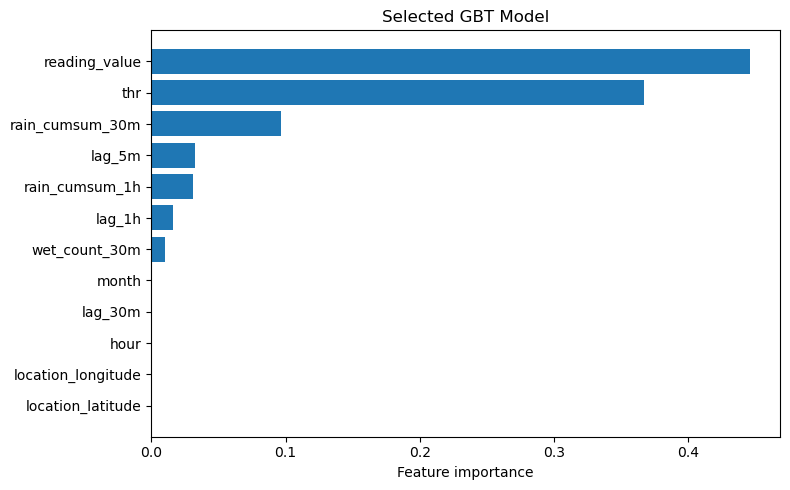

In [22]:
names = best_model.stages[0].getInputCols()
values = best_model.stages[-1].featureImportances.toArray()
 
importance = spark.createDataFrame(
    [(name, float(value)) for name, value in zip(names, values)],
    ["feature", "importance"]
)
 
importance.orderBy(F.desc("importance")).show(truncate=False)
 
importance.coalesce(1).write.mode("overwrite").parquet(
    OUTPUT + "/feature_importance"
)
 
# Collect only the small feature-importance table for plotting.
plot_data = importance.toPandas().sort_values("importance")
 
plt.figure(figsize=(8, 5))
plt.barh(plot_data["feature"], plot_data["importance"])
plt.xlabel("Feature importance")
plt.title("Selected GBT Model")
plt.tight_layout()
plt.show()